## Module 3: Computational Drug Discovery Project

Aerin Kim

Charlotte Lim

## Project Goal:

You are working as a Quantitative Systems Pharmacologist at the UVA Manning Institute for Biotechnology. Your overall goal is to help develop a GLP1 agonist drug for weight loss, branded Cavalitide, that will compete with semaglutide (Ozempic or Wegovy). Your project is composed of three tasks:
* Task 1: Fit a receptor binding (pharmacodynamics) model for Cavalitide
* Task 2: Simulate the pharmacokinetics of Cavalitide treatment
* Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment.

## Disease Background:
Provide a brief (<200 word) background of obesity, available treatments, and especially why improved treatments are needed. Your answers may include for example: 

**Prevalence & incidence:** As of August 2023, the prevalence of obesity in adults was 40.3% in the United States (Centers for Disease Control and Prevention, 2024). In 2024, 1 in 7 people in the world were living with obesity; this statistic corresponds to 1.1 billion people, 940 million of which were adults (World Health Organization, 2025). Obesity is generally measured by prevalence rather than incidence due to the long-term, chronic aspect of the condition rather than an exact or sudden event that causes it.

**Diagnosis & Symptoms:** Obesity is diagnosed using the body mass index (BMI) calculation, which multiplies weight in pounds by 703, divides by height in inches and then divides again by height in inches. A BMI of 30.0 or higher falls in the ‘Obese’ category (Mayo Clinic, 2023). For most individuals, BMI is a reasonable estimate of body fat, though there are exceptions with muscular athletes, since lean tissue isn’t considered in the calculation. Other methods like waist circumference measurements and DEXA scans serve as indicators/determinants of body fat (the latter being the most reliable tool).

In addition to excessive body fat, individuals with obesity commonly experience back pain,
fatigue, secondary hyperhidrosis (excessive sweating), insomnia/sleep apnea, joint pain, and the inability to perform physical tasks. Obesity also involves hormonal dysregulation and leptin resistance, perpetuating the weight gain cycle. Furthermore, obesity can have negative impacts mentally/psychologically, often leading to increased anxiety, depression, and disordered eating patterns (UKHS, n.d.). According to the American Psychological Association, it is probable that there is overlap between the risk factors for obesity and those for bulimia nervosa and binge-eating disorder (APA, 2022).

**Standard of care treatments (& reimbursement)**

**Disease progression & prognosis** 

**Biological mechanisms (anatomy, organ physiology, cell & molecular physiology)** 

**Clinical Trials/next-gen therapies**

Please provide citations and/or hyperlinks to where you obtained information (including AI) for each of the bullet points.

## Task 1: Fit a receptor binding model for Cavalitide:

Your colleague in Lead Discovery has identified a small molecule, Cavalitide, and performed experiments testing its binding to the GLP1 receptor (below, and available as cavalitide_data.csv). You now aim to develop a pharmacodynamics model of how GLP1 and Cavalitide can each bind and activate the GLP1 receptor. 

a)	Adapt your previous codes for modeling semaglutide (fit_semaglutide.py, semaglutide_data.csv) to fit the Cavalitide binding data.

b)	Show a plot of [Cavalitide] vs. Fraction active receptors (Fact) demonstrating a good fit.

c)	Provide the fitted value of Kd for Cavalitide. Interpret the Kd of Cavalitide versus that of semaglutide, commenting on advantages/disadvantages.

Brute-force Kd2 = 0.074 nM (SSE = 0.0054)
Fitted Kd2 = 0.077 nM (SSE = 0.0052)


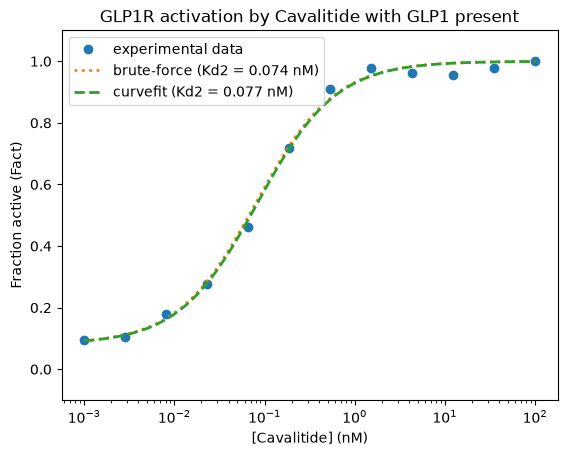

In [1]:
# fit_cavalitide_GLP1R.py

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Model: fractional receptor activation with two competing agonists L1 and L2
def Fact(L1, L2, Kd1, Kd2):
    """Fractional receptor activation with two agonists L1 and L2"""
    return (Kd2*L1+Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# Parameters [nM] -----------------------------------------------------------------------
Kd1 = 0.17 # L1, GLP1
L1 = 0.015 # [nM] GLP1 (fasting)
L2 = np.logspace(-3, 2, 500) # [nM] cavalitide (smooth x-axis for model curves)

# Load the Cavalitide data (column 1: [Cavalitide], column 2: Fact) --------------------------------------------------------------
data = np.loadtxt("cavalitide_data.csv", delimiter=",", skiprows=1)
L2_loaded, Fact_loaded = data[:, 0], data[:, 1]

# Approach 1: Brute force optimization of Kd2: try many candidate values in a for loop --------------------------------------------
Kd2_candidates = np.logspace(-3, 2, 100) # [nM]
SSE_brute = np.inf
for Kd2_try in Kd2_candidates:
    # Sum of squared errors between the data and the model for this candidate
    SSE = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_try))**2)
    if SSE < SSE_brute:
        SSE_brute = SSE
        Kd2_brute = Kd2_try
print(f"Brute-force Kd2 = {Kd2_brute:.3f} nM (SSE = {SSE_brute:.4f})") # print kd value

# Approach 2: Python curvefit of Kd2: related to steepest descent method ----------------------------------------------------------
popt, pcov = curve_fit(lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2), L2_loaded, Fact_loaded, p0=[0.1], bounds=(0, np.inf))
Kd2_fit = popt[0]
SSE_fit = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_fit))**2)
print(f"Fitted Kd2 = {Kd2_fit:.3f} nM (SSE = {SSE_fit:.4f})") # print kd value

# Plot: experimental data with both fitted model curves -----------------------------------------------------------------------
plt.figure()
plt.semilogx(L2_loaded, Fact_loaded, "o", label="experimental data")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_brute), ":", lw=2,
             label=f"brute-force (Kd2 = {Kd2_brute:.3f} nM)")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_fit), "--", lw=2,
             label=f"curvefit (Kd2 = {Kd2_fit:.3f} nM)")

plt.ylim(-0.1, 1.1)
plt.xlabel("[Cavalitide] (nM)")
plt.ylabel("Fraction active (Fact)")
plt.title("GLP1R activation by Cavalitide with GLP1 present")
plt.legend(loc="upper left")
plt.show()

As printed above, the fitted value of Kd2 for Cavalitide is 0.074nM for the Brute-force model and 0.077nM for the python fitted model. Cavalitide's Kd2 value is much lower than semiglutide's Kd2 value (0.38nM) and GLP1’s Kd value (0.17 nM). A lower Kd value means there is a higher bonding affinity between the drug and its receptor. A greater bonding affinity is advantageous since Calvatide will bind to its receptors at lower doses and remain bonded for longer periods of time compared to normal GLP1's in the body, even at fasting levels. However, a greater bindng affinity also could result in overstimulating the receptor with the body's normal GLP1 production.

## Task 2: Simulate the pharmacokinetics of Cavalitide treatment

Your boss is really excited about the progress of your team in Task 1 on the development of Cavalitide. You’re now assigned to help design the Phase 1 clinical trial for the pill version of Cavalitide. 

1. Review the example code for modeling semaglutide pharmacokinetics (semaglutidePK.py). Run simulations for both Ozempic (subcutaneous injection once per week) and Wegovy (daily pill).  Replace the portion of the code using an explicit Euler’s method with use of the more powerful built-in function scipy.integrate.solve_ivp. Rerun the code to create plots that compare the predicted profiles of Ozempic and Wegovy.
2. Now, adapt semaglutidePK.py to additionally incorporate simulations of Cavalitide (daily pill), which has an increased absorption rate ka = 0.006 1/h. Plot how Cavalitide blood concentration changes over time.
3. Given the higher absorption rate, you hypothesize that you can further optimize the dosing strategy. Adjust one or two drug or dosing specific parameters until you achieve a steady state blood concentration close to 0.5 nM. Plot your result. What did you change about the dosing strategy and why?

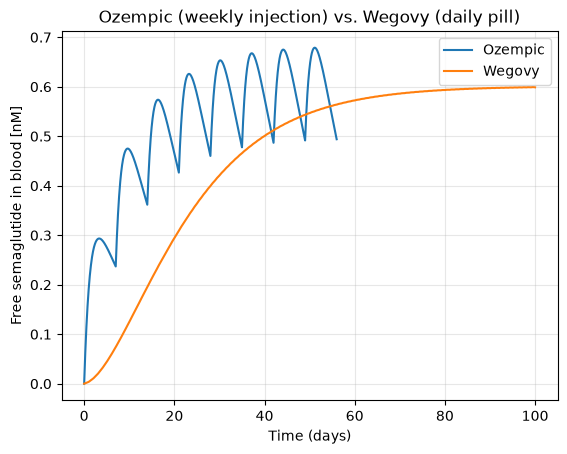

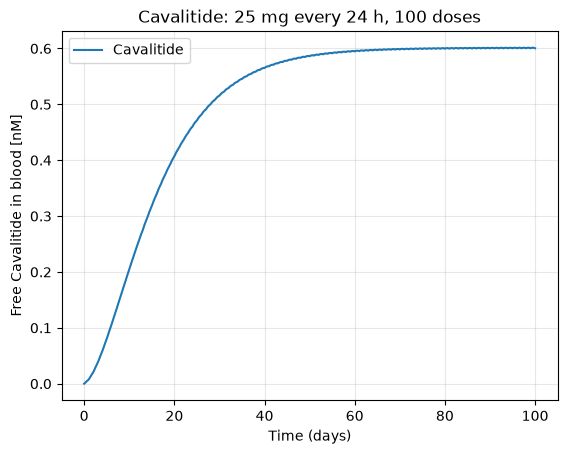

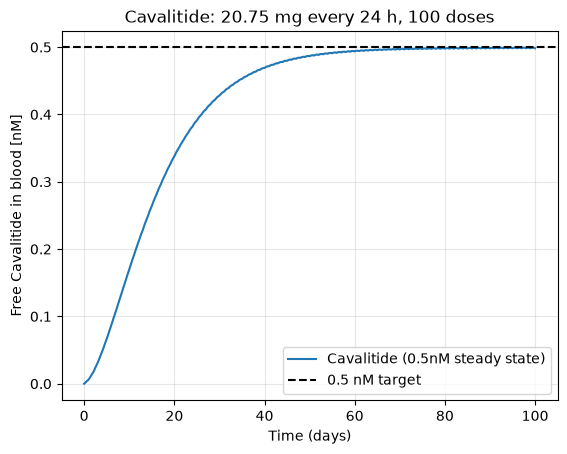

0.5nM Cavalitide steady state: 20.75mg every 24 h, for 100 doses


In [2]:
# cavalitidePK.py

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# product-specific parameters --------------------------------------------
products = {
    'Ozempic': dict(Favailable=0.89,   # bioavailability
                    ka=0.029,          # 1/h, absorption rate
                    D=2.0,             # mg per dose
                    interval=168,      # h between doses (weekly)
                    n_doses=8,         # number of doses
                    depot='subcutaneous'),
    'Wegovy':  dict(Favailable=0.01,
                    ka=0.0029,
                    D=25,              # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,
                    depot='gut (oral)'),
    # Cavalitide normal
    'Cavalitide': dict(Favailable=0.01, # lower Favailable, greater ka values
                       ka=0.006,
                       D=25,
                       interval=24,
                       n_doses=100,
                       depot='gut (oral)'),
    # Cavalitide dose lowered to ~0.5 nM steady state
    'Cavalitide (optimized)': dict(Favailable=0.01,
                                   ka=0.006,
                                   D=20.75,
                                   interval=24,
                                   n_doses=100,
                                   depot='gut (oral)'),
}

# shared model parameters --------------------------------------------
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # fraction free in blood (rest bound to albumin)

# simulation parameters --------------------------------------------
dt = 1.0        # h, spacing of saved output points

def simulate(drug):
    """Repeated dosing every `interval` h; returns time (h) and
    free blood concentration (nM)."""
    p = products[drug]
    Favailable, ka, D = p['Favailable'], p['ka'], p['D']
    interval, n_doses = p['interval'], p['n_doses']

    # ODEs: Asc = depot amount (mg), Cc = blood concentration (mg/L)
    def ODEfunc(t, y):
        Asc, Cc = y
        dAsc = -ka*Asc
        dCc = ka*Asc/V - ke*Cc
        return [dAsc, dCc]

    t_out, Cc_out = [], []
    y = np.array([0.0, 0.0])
    t_eval = np.arange(0, interval + dt/2, dt)   # output times within each interval
    for i in range(n_doses):
        y[0] += Favailable*D                     # absorbed fraction of dose enters the depot
        # solve_ivp replaces the explicit Euler loop for this dosing interval
        sol = solve_ivp(ODEfunc, [0, interval], y, t_eval=t_eval, rtol=1e-8, atol=1e-10)
        t_out.append(i*interval + sol.t)
        Cc_out.append(sol.y[1])
        y = sol.y[:, -1].copy()                  # carry state into next interval
    t = np.concatenate(t_out)
    Cc = np.concatenate(Cc_out)
    Cc_nM = Ffree * Cc * 1e-3 / MW * 1e9         # mg/L -> free nM
    return t, Cc_nM

# Run simulations --------------------------------------------
results = {drug: simulate(drug) for drug in products}

# Ozempic vs Wegovy --------------------------------------------
plt.figure()
for drug in ['Ozempic', 'Wegovy']:
    t, Cc = results[drug]
    plt.plot(t / 24, Cc, label=drug)
plt.xlabel("Time (days)")
plt.ylabel("Free semaglutide in blood [nM]")
plt.title("Ozempic (weekly injection) vs. Wegovy (daily pill)")
plt.legend()
plt.grid(alpha=0.3)

# Cavalitide blood concentration --------------------------------------------
plt.figure()
t, Cc = results['Cavalitide']
plt.plot(t / 24, Cc, label="Cavalitide")
plt.xlabel("Time (days)")
plt.ylabel("Free Cavalitide in blood [nM]")
plt.title("Cavalitide: 25 mg every 24 h, 100 doses")
plt.legend()
plt.grid(alpha=0.3)

# Cavalitide dosing w/ 0.5 nM target ------------------------------------------
plt.figure()
t, Cc = results['Cavalitide (optimized)']
plt.plot(t / 24, Cc, label="Cavalitide (0.5nM steady state)")
plt.axhline(0.5, color="k", ls="--", label="0.5 nM target")
plt.xlabel("Time (days)")
plt.ylabel("Free Cavalitide in blood [nM]")
plt.title("Cavalitide: 20.75 mg every 24 h, 100 doses")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

# steady-state value (last dosing interval) for the optimized dose
t, Cc = results['Cavalitide (optimized)']
print("0.5nM Cavalitide steady state: 20.75mg every 24 h, for 100 doses")

In order to reduce the steady state free Cavalitide in the blood, we reduced the dosage of mg of Cavalitide for each pill from 25mg to 20.75mg. The lower dosage causes there to not be too much Cavalitide in the blood, due to its greater absorption rate. Since Cavalitide is absorbed into the blood much more quicky than Wegovy, staying with a 25mg dose every day would cause an overdosage of the drug. Therefor, ~20.75mg of Cavalitide is the best dosage for patients taking the drug.

## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment

The Phase 1 clinical trial was a success, and you achieved the desired 0.5 nM concentration of Cavalitide in your patients. Now it’s time to further customize the dosing for the Phase 2 clinical trial, where you’re more interested in efficacy. You’ll need to combine the PK model (Task 2) and PD model (Task 1) to predict how the fraction of activated receptors changes over time.

1. Embed the ligand-receptor model of Cavalitide (from Task 1, but just using your optimized Kd) into your cavalitidePK.py model. Let’s call this combined model cavalitidePKPD.py. Predict how the fraction of active GLP1R receptors changes over the first 100 days of treatment. 
2. Further optimize your dosing strategy so that you achieve close to 90% active GLP1 receptors at steady state (around 100 days).  Which dosing parameters did you adjust? Provide an interpretation of the clinical benefits of this adjustment.


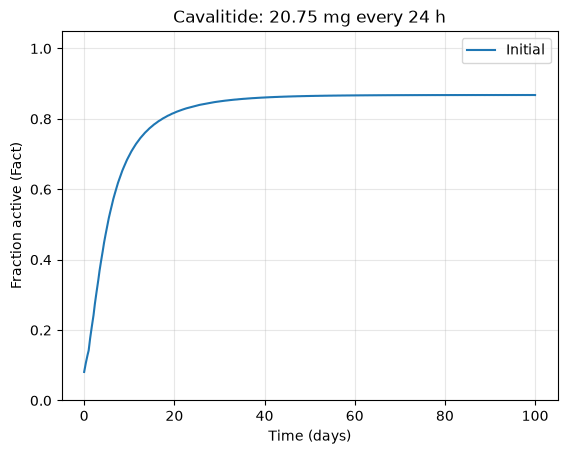

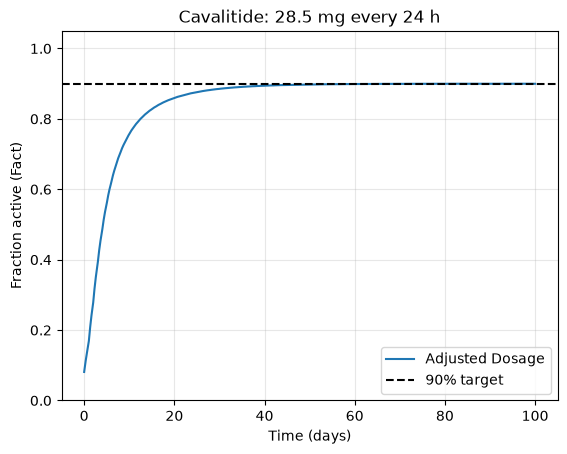

initial: free Cavalitide = 0.499 nM, Fact = 0.868
adjusted: free Cavalitide = 0.685 nM, Fact = 0.900


In [3]:
# cavalitidePKPD.py

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Fact model ------------------------------------------------------------------
def Fact(L1, L2, Kd1, Kd2):
    """Fractional receptor activation with two agonists L1 and L2"""
    return (Kd2*L1+Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# PD parameters [nM] ------------------------------------------------------------------
Kd1 = 0.17      # GLP1
Kd2 = 0.077     # Cavalitide (optimized fit from Task 1)
L1 = 0.015      # GLP1 (fasting)

# dosing regimens: initial (0.5 nM) and adjusted (~90% active receptors) ------------------------------------------------------------------
products = {
    'initial': dict(Favailable=0.01,   # bioavailability
                    ka=0.006,          # 1/h, absorption rate
                    D=20.75,            # mg per dose
                    interval=24,       # h between doses (daily)
                    n_doses=100),      # number of doses (100 days)
    'adjusted': dict(Favailable=0.01,
                    ka=0.006,
                    D=28.5,
                    interval=24,
                    n_doses=100),
}

# shared PK model parameters ------------------------------------------------------------------
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # fraction free in blood (rest bound to albumin)

# simulation parameters ------------------------------------------------------------------
dt = 1.0        # h, spacing of saved output points

def simulate(drug):
    """Repeated dosing every `interval` h; returns time (h), free blood
    concentration (nM) and fraction of active receptors."""
    p = products[drug]
    Favailable, ka, D = p['Favailable'], p['ka'], p['D']
    interval, n_doses = p['interval'], p['n_doses']

    # PK ODEs: Asc = depot amount (mg), Cc = blood concentration (mg/L)
    def ODEfunc(t, y):
        Asc, Cc = y
        dAsc = -ka*Asc
        dCc = ka*Asc/V - ke*Cc
        return [dAsc, dCc]

    t_out, Cc_out = [], []
    y = np.array([0.0, 0.0])
    t_eval = np.arange(0, interval + dt/2, dt)   # output times within each interval
    for i in range(n_doses):
        y[0] += Favailable*D                     # absorbed fraction of dose enters the depot
        sol = solve_ivp(ODEfunc, [0, interval], y, t_eval=t_eval,
                        rtol=1e-8, atol=1e-10)   # solve one dosing interval
        t_out.append(i*interval + sol.t)
        Cc_out.append(sol.y[1])
        y = sol.y[:, -1].copy()                  # carry state into next interval
    t = np.concatenate(t_out)
    Cc = np.concatenate(Cc_out)
    Cc_nM = Ffree * Cc * 1e-3 / MW * 1e9         # mg/L -> free nM
    Fact_t = Fact(L1, Cc_nM, Kd1, Kd2)           # PK output feeds the PD model
    return t, Cc_nM, Fact_t

# Simulations ------------------------------------------------------------------
results = {drug: simulate(drug) for drug in products}

# Initial dosing plot, Fact over 100 days ------------------------------------------------------------------
plt.figure()
t, Cc, Fact_t = results['initial']
plt.plot(t / 24, Fact_t, label="Initial")
plt.ylim(0, 1.05)
plt.xlabel("Time (days)")
plt.ylabel("Fraction active (Fact)")
plt.title(f"Cavalitide: {products['initial']['D']} mg every 24 h")
plt.legend()
plt.grid(alpha=0.3)

# Adjusted dosing plot w/ 90% target ---------------------------------------------------------------------
plt.figure()
t, Cc, Fact_t = results['adjusted']
plt.plot(t / 24, Fact_t, label="Adjusted Dosage")
plt.axhline(0.9, color="k", ls="--", label="90% target")
plt.ylim(0, 1.05)
plt.xlabel("Time (days)")
plt.ylabel("Fraction active (Fact)")
plt.title(f"Cavalitide: {products['adjusted']['D']} mg every 24 h")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

# Steady-state (last dosing interval) values ------------------------------------------------------------------
for drug in products:
    t, Cc, Fact_t = results[drug]
    print(f"{drug}: free Cavalitide = {Cc[-25:].mean():.3f} nM, Fact = {Fact_t[-25:].mean():.3f}")

The daily dosage of Cavalitide was adjusted to 28.5mg to raise the percentage of active GLP1R to 90% at steady state. Initially, the 20.75mg daily dosage resulted in a fact of 86.8%. In order to raise the Fact of Cavalitide, the dosage was raised to 28.5mg to achieve 90% active GLP1 receptors at steady state. The time between doses (24hrs) or number of doses (100) was kept the same in order to maintain an easy routine for patients. The greater Fact causes there to be more consistent GLP1 responses, increasing the weight loss benefits and other effects of the drug.

## Conclusions:

Explain what your analyses suggest about the potential for Cavalitide in competition with semaglutide (oral or injected).

## Limitations and Future Work:

Describe the limitations of your project. If you had more time or additional data, explain how you would improve the analysis.

## AI Usage Statement:

Claude AI was used for debugging the code for tasks 1, 2, and 3. No AI was used for writing the disease background, interpretations of the models, or in the conclusions, limitations, and future work.

## GitHub Repository Link:

GitHub [Link](https://github.com/charlottelim3/bme2315module3)


## References:

Centers for Disease Control and Prevention. (2024, September). Obesity and severe obesity prevalence in adults: United States, August 2021–August 2023. CDC. CDC.Gov. https://www.cdc.gov/nchs/products/databriefs/db508.htm
World Health Organization. (2025, May 7). Obesity and overweight. World Health Organization. https://www.who.int/news-room/fact-sheets/detail/obesity-and-overweight
Mayo Clinic. (2023, July 22). Obesity. Mayo Clinic. https://www.mayoclinic.org/diseases-conditions/obesity/symptoms-causes/syc-20375742
UKHS. (n.d.). Obesity causes & symptoms | the University of Kansas Health System. Www.Kansashealthsystem.Com. Retrieved November 15, 2026, from https://www.kansashealthsystem.com/care/conditions/obesity
APA. (2022). The neglect of obesity. Apa.Org. https://www.apa.org/monitor/mar02/sp
AACE. (2026). Patient journey obesity - treatment. American Association of Clinical Endocrinology. https://www.aace.com/patient-journey/obesity/patient-journey-obesity-treatment
, 8. Obesity Medicine Association. (2022). The four pillars of obesity treatment. Obesity Medicine Association. https://obesitymedicine.org/about/four-pillars/
Cleveland Clinic. (2024, September 10). Obesity & weight control: Health risks, weight loss & bariatric surgery. Cleveland Clinic. https://my.clevelandclinic.org/health/diseases/11209-weight-control-and-obesity
Busebee, B., Ghusn, W., Cifuentes, L., & Acosta, A. (2023). Obesity: A review of pathophysiology and classification. Mayo Clinic Proceedings, 98(12). https://doi.org/10.1016/j.mayocp.2023.05.026


## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*